In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set a random seed so that the same random values
# are generated each time the code runs
np.random.seed(42)

# Create a list of city names
cities = [
    "London", "Paris", "New York", "Tokyo", "Sydney",
    "Berlin", "Toronto", "Dubai", "Singapore", "Cape Town"
]

# Create a list of month names
months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Define realistic average monthly temperatures (°C). These values roughly reflect typical climate patterns for each city throughout the year. This is better than just doing a random generator of temperatures from -5 to -35 as this creates anomolies across cities and seasons.
base_temps = {
    "London":    [5, 6, 8, 11, 15, 18, 21, 21, 18, 14, 9, 6],
    "Paris":     [4, 5, 9, 12, 16, 20, 23, 23, 19, 14, 8, 5],
    "New York":  [0, 2, 7, 13, 18, 24, 27, 26, 22, 16, 10, 4],
    "Tokyo":     [5, 6, 9, 15, 20, 23, 27, 29, 25, 19, 13, 8],
    "Sydney":    [23, 23, 22, 19, 16, 13, 12, 13, 16, 18, 20, 22],
    "Berlin":    [0, 2, 6, 10, 15, 18, 20, 20, 16, 11, 6, 2],
    "Toronto":   [-5, -3, 2, 8, 15, 20, 24, 23, 18, 11, 5, -1],
    "Dubai":     [19, 21, 24, 29, 33, 35, 37, 37, 34, 30, 26, 21],
    "Singapore": [27, 28, 28, 28, 28, 28, 28, 28, 28, 28, 27, 27],
    "Cape Town": [25, 25, 23, 20, 17, 15, 14, 15, 16, 18, 21, 23]
}

# Define how much each city's temperatures are allowed to vary from the average temperatures
# Cities with stable climates have lower values
city_variability = {
    "London": 1.0,
    "Paris": 1.0,
    "New York": 2.0,
    "Tokyo": 1.5,
    "Sydney": 1.0,
    "Berlin": 1.5,
    "Toronto": 2.5,
    "Dubai": 0.8,
    "Singapore": 0.5,
    "Cape Town": 1.0
}

# Create an empty list to store the final temperature data
temperature_data = []

# Generate realistic temperatures for each city
for city in cities:

    # Convert the city's monthly average temperatures to a NumPy array
    temps = np.array(base_temps[city])

    # Generate random variation around the average temperature
    # using a normal distribution
    noise = np.random.normal(
        loc=0,
        scale=city_variability[city],
        size=12
    )

    # Add the variation to the average temperatures
    realistic_temps = temps + noise

    # Prevent unrealistic temperature spikes by restricting
    # temperatures to within ±3°C of the average
    realistic_temps = np.clip(
        realistic_temps,
        temps - 3,
        temps + 3
    )

    # Add the city's temperature data to the dataset
    temperature_data.append(realistic_temps)

# Convert the temperature data into a Pandas DataFrame
# Cities become row labels and months become column labels
weather_df = pd.DataFrame(
    temperature_data,
    index=cities,
    columns=months
)

# Round values to 1 decimal place for readability
weather_df = weather_df.round(1)

# Display the completed dataset
print("Average Monthly Temperatures (°C)")
print(weather_df)

Average Monthly Temperatures (°C)
            Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov  \
London      5.5   5.9   8.6  12.5  14.8  17.8  22.6  21.8  17.5  14.5   8.5   
Paris       4.2   3.1   7.3  11.4  15.0  20.3  22.1  21.6  20.5  13.8   8.1   
New York   -1.1   2.2   4.7  13.8  16.8  23.4  25.8  29.0  22.0  13.9  11.6   
Tokyo       5.3   3.1   7.0  15.3  21.1  23.3  26.8  28.5  22.8  17.9  12.3   
Sydney     23.3  21.2  22.3  18.6  15.3  13.6  13.0  13.9  15.2  17.7  20.3   
Berlin     -0.7   1.7   4.3   8.2  16.2  20.0  19.9  21.5  16.5  10.0   6.5   
Toronto    -5.1   0.0  -1.0  10.1  15.2  19.3  24.2  20.0  17.5  11.9   8.0   
Dubai      18.4  20.6  24.7  29.3  32.6  35.4  37.1  37.8  33.4  29.7  25.7   
Singapore  27.1  28.1  28.0  27.9  27.3  27.8  27.8  27.6  27.9  28.2  27.9   
Cape Town  25.3  24.9  21.1  20.0  17.1  17.5  13.8  15.3  16.0  16.8  22.1   

            Dec  
London      5.5  
Paris       3.6  
New York    1.6  
Tokyo       9.6  
Sydney

In [5]:
# Calculate annual average temperature for each city
annual_avg_temp = weather_df.mean(axis=1)

print("Annual Average Temperature (°C)")
print(annual_avg_temp.round(1))

annual_avg_temp = weather_df.mean(axis=1)

Annual Average Temperature (°C)
London       13.0
Paris        12.6
New York     13.6
Tokyo        16.1
Sydney       18.1
Berlin       10.7
Toronto       9.8
Dubai        28.7
Singapore    27.7
Cape Town    19.5
dtype: float64


In [7]:
# Find the warmest and coldest cities
highest_avg_city = annual_avg_temp.idxmax()
lowest_avg_city = annual_avg_temp.idxmin()

# Get their average temperatures
highest_avg_temp = annual_avg_temp.max()
lowest_avg_temp = annual_avg_temp.min()

print(f"Highest average temperature: {highest_avg_city} ({highest_avg_temp:.1f}°C)")
print(f"Lowest average temperature: {lowest_avg_city} ({lowest_avg_temp:.1f}°C)")

# Calculate annual average temperature for each city
annual_avg_temp = weather_df.mean(axis=1)

print(annual_avg_temp.round(1))

annual_avg_temp = weather_df.mean(axis=1).round(1)

print("Annual Average Temperature (°C)")
print(annual_avg_temp)

# City with highest average temperature
warmest_city = annual_avg_temp.idxmax()

# City with lowest average temperature
coldest_city = annual_avg_temp.idxmin()

print(f"Warmest city: {warmest_city}")
print(f"Coldest city: {coldest_city}")






Highest average temperature: Dubai (28.7°C)
Lowest average temperature: Toronto (9.8°C)
London       13.0
Paris        12.6
New York     13.6
Tokyo        16.1
Sydney       18.1
Berlin       10.7
Toronto       9.8
Dubai        28.7
Singapore    27.7
Cape Town    19.5
dtype: float64
Annual Average Temperature (°C)
London       13.0
Paris        12.6
New York     13.6
Tokyo        16.1
Sydney       18.1
Berlin       10.7
Toronto       9.8
Dubai        28.7
Singapore    27.7
Cape Town    19.5
dtype: float64
Warmest city: Dubai
Coldest city: Toronto


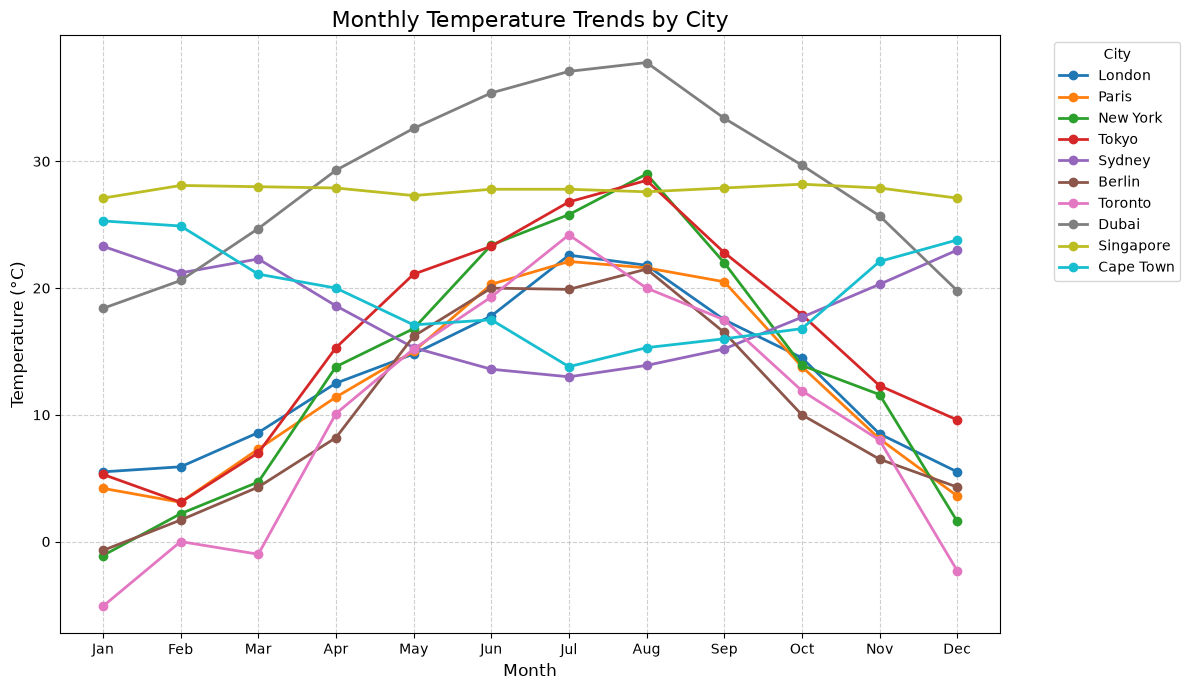

In [12]:
# Create the chart
plt.figure(figsize=(12, 7))

# Plot one line per city
for city in weather_df.index:
    plt.plot(
        weather_df.columns,
        weather_df.loc[city],
        marker='o',
        linewidth=2,
        label=city
    )

# Add titles and labels
plt.title('Monthly Temperature Trends by City', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)

# Add grid and legend
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(
    title='City',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

# Improve layout
plt.tight_layout()

# Display the chart
plt.show()


# Temperature Analysis Report

## Overview

This analysis examined monthly average temperatures for ten cities throughout a full year. Annual average temperatures were calculated for each city and visualised using a line chart showing monthly temperature trends.

## Key Findings

- **Dubai** recorded the highest annual average temperature at **28.7°C**, making it the warmest city in the dataset.
- **Toronto** recorded the lowest annual average temperature at **9.8°C**, making it the coldest city in the dataset.

## Annual Average Temperatures

| City | Annual Average Temperature (°C) |
|------|-------------------------------:|
| London | 13.0 |
| Paris | 12.6 |
| New York | 13.6 |
| Tokyo | 16.1 |
| Sydney | 18.1 |
| Berlin | 10.7 |
| Toronto | 9.8 |
| Dubai | 28.7 |
| Singapore | 27.7 |
| Cape Town | 19.5 |

## Temperature Trends

Several notable patterns can be observed from the visualisation:

1. **Dubai and Singapore** maintained consistently high temperatures throughout the year. Singapore exhibited the most stable climate, with temperatures remaining close to 28°C in every month.

2. **London, Paris, Berlin, New York, and Toronto** displayed clear seasonal patterns typical of Northern Hemisphere locations. Temperatures generally increased from winter to summer, reaching a peak between July and August before declining towards the end of the year.

3. **Toronto** showed the greatest seasonal variation, with temperatures below freezing during the winter months and much warmer summer temperatures reaching approximately 24°C.

4. **Sydney and Cape Town**, both located in the Southern Hemisphere, followed the opposite seasonal trend to Northern Hemisphere cities. Their highest temperatures occurred around January and December, while their coolest temperatures were observed during the middle